# Problem 3 · Temperatures at four interior points of a square plate

**simple_CFD · Introduction to Computational Fluid Dynamics with the Finite Difference Method**

> *In the figure, calculate the temperatures at points 1, 2, 3 and 4 using the numerical method (the Finite Difference Method). The edges of the square are held at 700 °C (top), 100 °C (left), 400 °C (right) and 500 °C (bottom).*

This is our first **two-dimensional** problem. We solve it **step by step, following the 7 pillars of CFD**:

| Pillar | What we do here |
|:-:|---|
| 1 · Geometry | describe the plate and its edge temperatures |
| 2 · Grid | number the nodes with two indices $(i, j)$ |
| 3 · Physics | the steady 2D heat equation (Laplace equation) |
| 4 · Numerical scheme | the five-point formula → one algebraic equation per node |
| 5 · Solution setup | Gaussian elimination (direct) and Gauss–Seidel iteration |
| 6 · Compute | solve the 4 equations both ways |
| 7 · Post-processing | temperature picture, energy check, and a finer grid to see how good 4 nodes are |

> **Plain Python only.** All numerical work uses ordinary Python lists and `for` loops, so you can follow every number. The only import used in the calculations is `math` (part of Python itself), for the exact series solution. The figures are drawn by `plots.py` (with matplotlib); you do not need to open it to follow the method.

In [1]:
import math     # built into Python: sin, exp, pi (only for the exact solution)
import plots    # our drawing helpers (plots.py)

---
## Pillar 1 · The physical problem and its geometry

A square plate (or the square cross-section of a long bar) has its four edges held at fixed temperatures. Heat flows **from the hot edges to the cold edges** through the plate. After a long time the temperatures stop changing: the plate reaches **steady state**. We want the temperature at four points inside it.

The square is divided into $3 \times 3$ equal squares, so the grid spacing is the same in both directions, $\Delta x = \Delta y$. The size of the plate and its conductivity are **not needed**: as we will see, they cancel out of the equations.

**Assumptions:** steady state; two-dimensional conduction (no temperature change through the thickness); no heat generated inside the plate; constant thermal conductivity $k$.

In [2]:
# ---- edge temperatures [°C] ----------------------------------------------
T_top = 700.0
T_left = 100.0
T_right = 400.0
T_bottom = 500.0

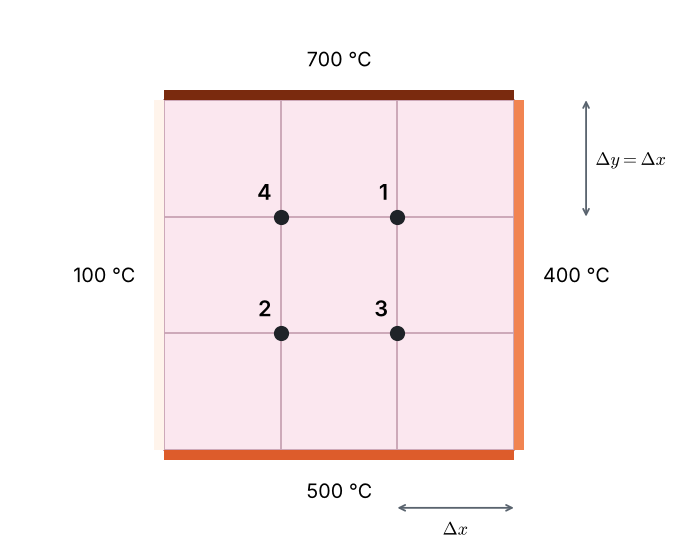

In [3]:
plots.schematic(T_top, T_left, T_right, T_bottom)

---
## Pillar 2 · The grid

The grid lines cross at $4 \times 4 = 16$ points, the **nodes**. In 2D every node gets **two indices**: $i$ counts along $x$ (left to right) and $j$ along $y$ (bottom to top), both from $0$ to $M = 3$.

* The 12 nodes **on the edges** have known temperatures (*Dirichlet* boundary conditions).
* The 4 nodes **inside** are unknown. They are the numbered points of the figure: node 4 is $(i, j) = (1, 2)$, node 1 is $(2, 2)$, node 2 is $(1, 1)$ and node 3 is $(2, 1)$.
* The 4 **corner** nodes belong to two edges at once, which have different temperatures. Luckily, as we will see, the corners are **never used** by the method.

The function `boundary_value` returns the known temperature of an edge node. It works for any number of squares $M$, which we will use later for finer grids.

In [4]:
M = 3                                            # number of squares along each side

nodes = {1: (2, 2), 2: (1, 1), 3: (2, 1), 4: (1, 2)}   # node number -> (i, j)


def boundary_value(i, j, M):
    """Known temperature of edge node (i, j); None for interior nodes and corners."""
    if j == M and 0 < i < M:
        return T_top
    if j == 0 and 0 < i < M:
        return T_bottom
    if i == 0 and 0 < j < M:
        return T_left
    if i == M and 0 < j < M:
        return T_right
    return None


# print the grid row by row, top row first ("??" = unknown, "--" = corner)
for j in range(M, -1, -1):
    row = []
    for i in range(M + 1):
        value = boundary_value(i, j, M)
        if value is not None:
            row.append(f"{value:6.0f}")
        elif (i, j) in nodes.values():
            number = [n for n, ij in nodes.items() if ij == (i, j)][0]
            row.append(f"   T{number}")
        else:
            row.append("    --")
    print(f"j = {j}: " + "".join(row))

j = 3:     --   700   700    --
j = 2:    100   T4   T1   400
j = 1:    100   T2   T3   400
j = 0:     --   500   500    --


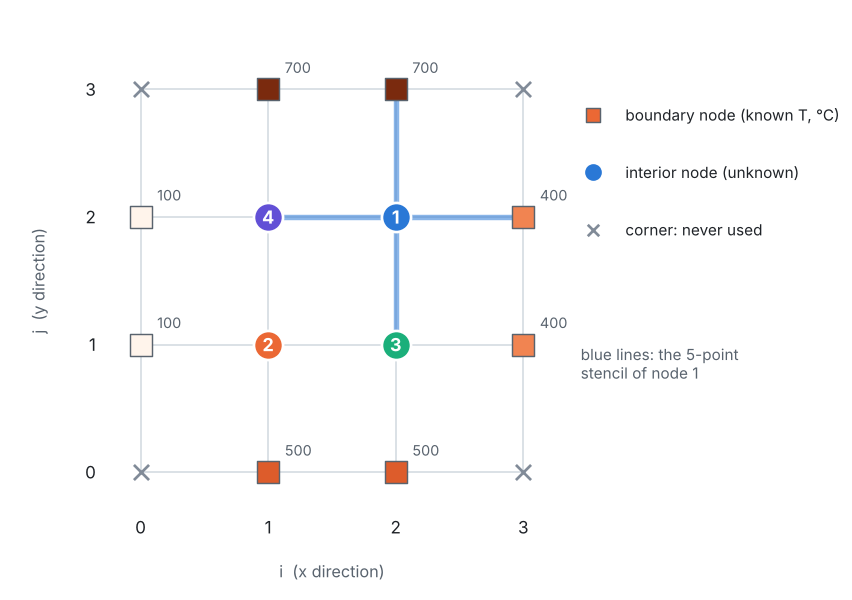

In [5]:
plots.grid(M, nodes, boundary_value)

---
## Pillar 3 · Physics: the governing equation

Take a small rectangle of the plate, $dx$ by $dy$. In steady state and without heat generation, **the heat conducted in must equal the heat conducted out**. With Fourier's law, $q = -k \cdot \text{area} \cdot \partial T/\partial n$, this energy balance gives the **steady two-dimensional heat equation**, also called the **Laplace equation**:

$$\frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2} = 0.$$

The conductivity $k$ has dropped out: for steady conduction with constant $k$, the temperature field does not depend on the material. The **boundary conditions** are the four edge temperatures.

### An exact solution, for checking

The Laplace equation is *linear*, so the solution can be built by **superposition**: split the problem into four simpler ones, each with only one non-zero edge, and add them up. Each simple problem is solved by separation of variables. For a unit square with temperature 1 on the edge $\eta = 1$ and 0 on the others,

$$S(\xi, \eta) = \sum_{n = 1, 3, 5, \dots} \frac{4}{n\pi}\,\sin(n\pi\xi)\,\frac{\sinh(n\pi\eta)}{\sinh(n\pi)},$$

and the full solution is

$$T(x, y) = T_{top}\,S(x, y) + T_{bottom}\,S(x, 1 - y) + T_{left}\,S(y, 1 - x) + T_{right}\,S(y, x).$$

This infinite series is much harder to use than the numerical method, but it is exact. We code it only to check our FDM answers.

In [6]:
def S(xi, eta, terms=200):
    """Series solution with temperature 1 on the edge eta = 1 and 0 on the others."""
    total = 0.0
    for n in range(1, 2 * terms, 2):                   # n = 1, 3, 5, ...
        a, b = n * math.pi * eta, n * math.pi
        sinh_ratio = math.exp(a - b) * (1 - math.exp(-2 * a)) / (1 - math.exp(-2 * b))
        total += 4 / (n * math.pi) * math.sin(n * math.pi * xi) * sinh_ratio   # sinh(a)/sinh(b)
    return total


def T_exact(x, y):
    """Exact temperature at (x, y) in a unit square (x, y between 0 and 1)."""
    return (T_top * S(x, y) + T_bottom * S(x, 1 - y)
            + T_left * S(y, 1 - x) + T_right * S(y, x))


exact = {n: T_exact(i / M, j / M) for n, (i, j) in nodes.items()}
for n in (1, 2, 3, 4):
    print(f"exact temperature at node {n}: {exact[n]:8.3f} °C")

exact temperature at node 1:  490.359 °C
exact temperature at node 2:  359.641 °C
exact temperature at node 3:  438.072 °C
exact temperature at node 4:  411.928 °C


> The ratio $\sinh(n\pi\eta)/\sinh(n\pi)$ is written with exponentials, because `math.sinh` overflows for large $n$.

---
## Pillar 4 · Numerical scheme: the five-point formula

At an interior node $(i, j)$ we replace each second derivative by a **central difference** (error $\mathcal{O}(\Delta x^2)$):

$$\frac{\partial^2 T}{\partial x^2} \approx \frac{T_{i+1,j} - 2T_{i,j} + T_{i-1,j}}{\Delta x^2}, \qquad
\frac{\partial^2 T}{\partial y^2} \approx \frac{T_{i,j+1} - 2T_{i,j} + T_{i,j-1}}{\Delta y^2}.$$

With $\Delta x = \Delta y$, the Laplace equation becomes, after multiplying by $\Delta x^2$,

$$T_{i+1,j} + T_{i-1,j} + T_{i,j+1} + T_{i,j-1} - 4\,T_{i,j} = 0
\qquad\Longleftrightarrow\qquad
T_{i,j} = \frac{T_E + T_W + T_N + T_S}{4}.$$

**Every node is the average of its four neighbours** (east, west, north, south). The grid spacing has cancelled too, so the size of the plate is not needed. Note that the formula only uses the four *side* neighbours: the corner nodes never appear.

Writing it for our four nodes (known neighbours moved to the right-hand side):

| node | east | west | north | south | equation |
|:-:|:-:|:-:|:-:|:-:|---|
| 1 | 400 | $T_4$ | 700 | $T_3$ | $4T_1 - T_3 - T_4 = 1100$ |
| 2 | $T_3$ | 100 | $T_4$ | 500 | $4T_2 - T_3 - T_4 = 600$ |
| 3 | 400 | $T_2$ | $T_1$ | 500 | $4T_3 - T_1 - T_2 = 900$ |
| 4 | $T_1$ | 100 | 700 | $T_2$ | $4T_4 - T_1 - T_2 = 800$ |

Instead of writing these by hand, the code below **assembles** them automatically: for every unknown node it looks at its four neighbours; an unknown neighbour goes into the matrix $A$ (coefficient $-1$), a known edge temperature goes into the right-hand side $b$. The result is the linear system $A\,\mathbf{T} = \mathbf{b}$ with $\mathbf{T} = [T_1, T_2, T_3, T_4]$.

In [7]:
order = [1, 2, 3, 4]                                   # order of the unknowns in the vector T
row_of = {nodes[n]: k for k, n in enumerate(order)}    # (i, j) -> row number in A

A = [[0.0] * 4 for _ in range(4)]
b = [0.0] * 4
for k, n in enumerate(order):
    i, j = nodes[n]
    A[k][k] = 4.0                                      # 4 T_P ...
    for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):  # east, west, north, south
        neighbour = (i + di, j + dj)
        if neighbour in row_of:                        # unknown neighbour: stays on the left
            A[k][row_of[neighbour]] -= 1.0
        else:                                          # known edge temperature: goes to the right
            b[k] += boundary_value(neighbour[0], neighbour[1], M)

for k, n in enumerate(order):
    terms = "  ".join(f"{A[k][c]:+.0f}·T{order[c]}" for c in range(4) if A[k][c] != 0)
    print(f"node {n}:  {terms:30s} = {b[k]:6.0f}")

node 1:  +4·T1  -1·T3  -1·T4            =   1100
node 2:  +4·T2  -1·T3  -1·T4            =    600
node 3:  -1·T1  -1·T2  +4·T3            =    900
node 4:  -1·T1  -1·T2  +4·T4            =    800


---
## Pillar 5 · Solution setup: two ways to solve $A\,\mathbf{T} = \mathbf{b}$

### A · Gaussian elimination (direct)

The method you know from algebra, done systematically:

1. **Forward elimination.** Use row 1 to remove $T_1$ from the rows below it, then row 2 to remove $T_2$ from the rows below it, and so on. The matrix becomes *upper triangular*.
2. **Back substitution.** The last row now contains only one unknown: solve it, then move up row by row.

The code prints the augmented matrix $[A \,|\, \mathbf{b}]$ after each elimination step, so you can follow it with pen and paper. (Our matrix has large diagonal entries, so we never divide by zero; general-purpose codes also swap rows, called *pivoting*, to be safe.)

### B · Gauss–Seidel iteration (iterative)

Use the five-point formula directly as an update rule: replace each $T_P$ by the average of its neighbours, using the newest values, and repeat until nothing changes any more. It needs a **starting guess**; we use 400 °C, a round number in the middle of the edge temperatures. (Any guess works; a good one just saves iterations.)

| | Gaussian elimination | Gauss–Seidel |
|---|---|---|
| type | direct | iterative |
| result | exact (up to round-off) after a fixed number of steps | improves with every iteration |
| 👍 | no guess, no tolerance | very simple; tiny memory; ideal for large grids |
| 👎 | cost grows like $n^3$ for $n$ unknowns | needs a guess, a tolerance, and can be slow |

In [8]:
def show(Ab, title):
    """Print an augmented matrix [A | b]."""
    print(title)
    for row in Ab:
        print("   [" + "".join(f"{v:9.3f}" for v in row[:-1]) + "  |" + f"{row[-1]:10.3f} ]")
    print()


def gaussian_elimination(A, b, verbose=False):
    """Solve A x = b by forward elimination and back substitution."""
    n = len(b)
    Ab = [A[r][:] + [b[r]] for r in range(n)]          # augmented matrix [A | b]
    if verbose:
        show(Ab, "start:")

    # forward elimination: create zeros below the diagonal, column by column
    for p in range(n - 1):                             # p = pivot row
        for r in range(p + 1, n):                      # every row below the pivot
            factor = Ab[r][p] / Ab[p][p]
            for c in range(p, n + 1):
                Ab[r][c] -= factor * Ab[p][c]
        if verbose:
            show(Ab, f"after removing T{order[p]} from the rows below row {p + 1}:")

    # back substitution: from the last row up to the first
    x = [0.0] * n
    for r in range(n - 1, -1, -1):
        total = Ab[r][n]
        for c in range(r + 1, n):
            total -= Ab[r][c] * x[c]
        x[r] = total / Ab[r][r]
    return x

In [9]:
def gauss_seidel(A, b, T_start, tol=1e-4, max_iter=500):
    """Solve A x = b by Gauss-Seidel iteration; also return every iterate."""
    T = T_start[:]
    table = [T[:]]                                     # the guess, then every iteration
    changes = []
    for iteration in range(max_iter):
        largest_change = 0.0
        for k in range(len(b)):
            total = b[k]
            for c in range(len(b)):
                if c != k:
                    total -= A[k][c] * T[c]
            new_value = total / A[k][k]
            largest_change = max(largest_change, abs(new_value - T[k]))
            T[k] = new_value                           # use the new value immediately
        table.append(T[:])
        changes.append(largest_change)
        if largest_change < tol:
            break
    return T, table, changes

---
## Pillar 6 · Compute

### A · Gaussian elimination, step by step

In [10]:
T_direct = gaussian_elimination(A, b, verbose=True)

for k, n in enumerate(order):
    print(f"T{n} = {T_direct[k]:.3f} °C")

start:
   [    4.000    0.000   -1.000   -1.000  |  1100.000 ]
   [    0.000    4.000   -1.000   -1.000  |   600.000 ]
   [   -1.000   -1.000    4.000    0.000  |   900.000 ]
   [   -1.000   -1.000    0.000    4.000  |   800.000 ]

after removing T1 from the rows below row 1:
   [    4.000    0.000   -1.000   -1.000  |  1100.000 ]
   [    0.000    4.000   -1.000   -1.000  |   600.000 ]
   [    0.000   -1.000    3.750   -0.250  |  1175.000 ]
   [    0.000   -1.000   -0.250    3.750  |  1075.000 ]

after removing T2 from the rows below row 2:
   [    4.000    0.000   -1.000   -1.000  |  1100.000 ]
   [    0.000    4.000   -1.000   -1.000  |   600.000 ]
   [    0.000    0.000    3.500   -0.500  |  1325.000 ]
   [    0.000    0.000   -0.500    3.500  |  1225.000 ]

after removing T3 from the rows below row 3:
   [    4.000    0.000   -1.000   -1.000  |  1100.000 ]
   [    0.000    4.000   -1.000   -1.000  |   600.000 ]
   [    0.000    0.000    3.500   -0.500  |  1325.000 ]
   [    0.000  

### B · Gauss–Seidel, iteration by iteration

In [11]:
tol = 1e-4
T_guess = 400.0                                       # starting guess for all four nodes [°C]
T_iter, table, changes = gauss_seidel(A, b, [T_guess] * 4, tol)

print(" iter        T1         T2         T3         T4    largest change")
for it, row in enumerate(table):
    change = f"{changes[it - 1]:12.5f}" if it > 0 else ""
    print(f"{it:4d}  " + "".join(f"{v:10.4f} " for v in row) + change)

 iter        T1         T2         T3         T4    largest change
   0    400.0000   400.0000   400.0000   400.0000 
   1    475.0000   350.0000   431.2500   406.2500     75.00000
   2    484.3750   359.3750   435.9375   410.9375      9.37500
   3    486.7188   361.7188   437.1094   412.1094      2.34375
   4    487.3047   362.3047   437.4023   412.4023      0.58594
   5    487.4512   362.4512   437.4756   412.4756      0.14648
   6    487.4878   362.4878   437.4939   412.4939      0.03662
   7    487.4969   362.4969   437.4985   412.4985      0.00916
   8    487.4992   362.4992   437.4996   412.4996      0.00229
   9    487.4998   362.4998   437.4999   412.4999      0.00057
  10    487.5000   362.5000   437.5000   412.5000      0.00014
  11    487.5000   362.5000   437.5000   412.5000      0.00004


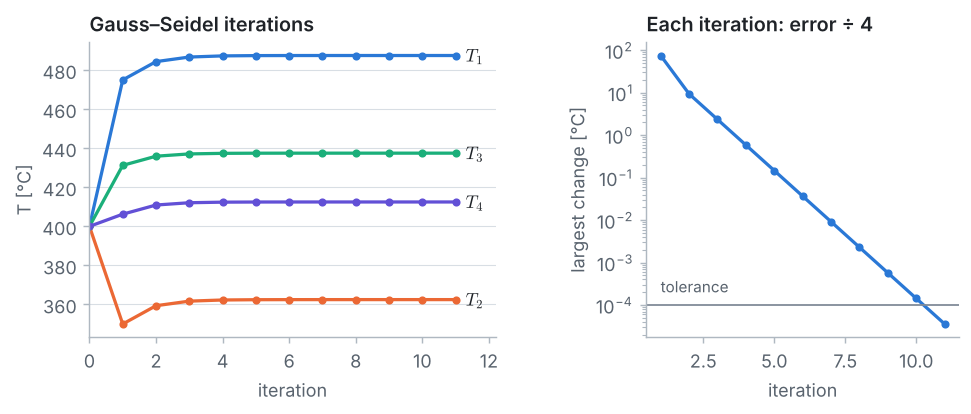

In [12]:
plots.iterations(table, (changes, tol))

Both methods give the same temperatures. Gauss–Seidel needs only about ten iterations here, because each iteration shrinks the error by a factor of about 4 (right panel). On large grids this factor gets much closer to 1, and plain Gauss–Seidel becomes slow.

---
## Pillar 7 · Post-processing

### The answer

In [13]:
T_solution = {n: T_direct[k] for k, n in enumerate(order)}
for n in (1, 2, 3, 4):
    print(f"T{n} = {T_solution[n]:6.1f} °C")

T1 =  487.5 °C
T2 =  362.5 °C
T3 =  437.5 °C
T4 =  412.5 °C


### Energy check: heat in = heat out

In steady state, the heat entering the plate through the hot edges must leave through the cold edges. Between an edge node $B$ and its interior neighbour $P$, Fourier's law gives the heat flow (per unit depth of plate)

$$q' = k\,\Delta y\,\frac{T_B - T_P}{\Delta x} = k\,(T_B - T_P) \qquad (\Delta x = \Delta y),$$

so $q'/k = T_B - T_P$, positive when heat flows *into* the plate. The function below adds this up along each edge. It works on a temperature grid `T[j][i]` of any size.

In [14]:
def edge_heat_flows(T, M):
    """q'/k [K] through each edge (positive = into the plate) for a grid T[j][i]."""
    flows = {"top": 0.0, "bottom": 0.0, "left": 0.0, "right": 0.0}
    for j in range(1, M):
        for i in range(1, M):                          # every interior node P ...
            for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                ni, nj = i + di, j + dj                # ... and each of its neighbours
                if nj == M:
                    flows["top"] += T[nj][ni] - T[j][i]
                elif nj == 0:
                    flows["bottom"] += T[nj][ni] - T[j][i]
                elif ni == 0:
                    flows["left"] += T[nj][ni] - T[j][i]
                elif ni == M:
                    flows["right"] += T[nj][ni] - T[j][i]
    return flows


# the coarse solution as a 4 x 4 grid (corners stay None: they are never used)
T_grid = [[boundary_value(i, j, M) for i in range(M + 1)] for j in range(M + 1)]
for n, (i, j) in nodes.items():
    T_grid[j][i] = T_solution[n]

flows = edge_heat_flows(T_grid, M)
for edge, q in flows.items():
    print(f"{edge:>6s} edge:  q'/k = {q:+7.1f} K   ({'in' if q > 0 else 'out'})")
print(f"   sum:          {sum(flows.values()):+7.1f} K")

   top edge:  q'/k =  +500.0 K   (in)
bottom edge:  q'/k =  +200.0 K   (in)
  left edge:  q'/k =  -575.0 K   (out)
 right edge:  q'/k =  -125.0 K   (out)
   sum:             +0.0 K


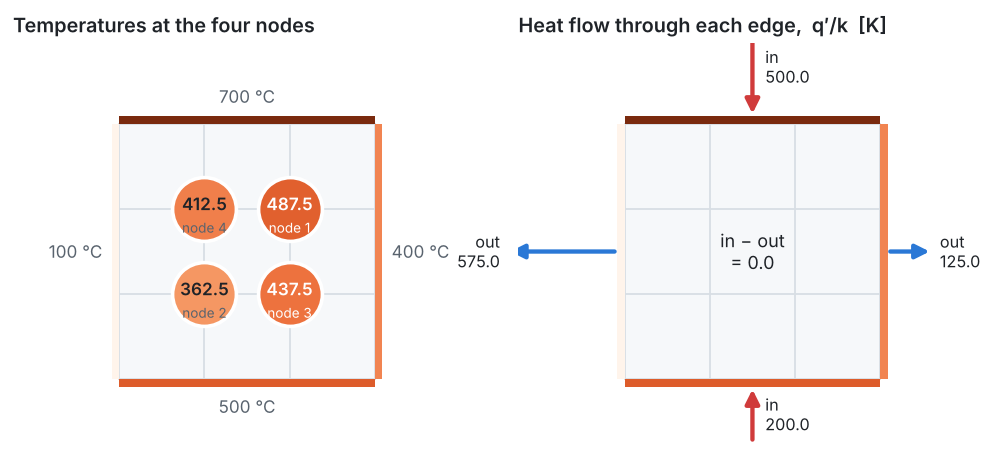

In [15]:
plots.plate(T_solution, T_top, T_left, T_right, T_bottom, flows)

Heat enters through the top (700 °C) and bottom (500 °C) edges and leaves through the left (100 °C) and right (400 °C) edges, and the total is **exactly zero**. This is not luck: the sum over all edges is the sum of all the node equations, each of which is zero. The finite difference solution conserves energy. (The values per edge are only rough estimates on such a coarse grid.)

### How good is a grid with only four interior nodes?

To find out, we solve the same plate on finer grids with $M = 6, 12, 24, 48$ and $96$ squares per side. The points 1–4 are always at $x, y = \tfrac{1}{3}, \tfrac{2}{3}$ of the side, so they remain grid nodes when $M$ is a multiple of 3.

With thousands of unknowns we no longer build the matrix: we apply the five-point formula directly on the grid. To speed up Gauss–Seidel we use **successive over-relaxation (SOR)**: each update is pushed a bit further than Gauss–Seidel would go, by a factor $\omega$ between 1 and 2 ($\omega = 1$ is plain Gauss–Seidel). For this problem the best value is $\omega = 2/(1 + \sin(\pi/M))$.

In [16]:
def solve_plate(M, tol=1e-6):
    """Temperatures T[j][i] on a plate with M x M squares, by SOR iteration."""
    omega = 2.0 / (1.0 + math.sin(math.pi / M))        # best over-relaxation factor
    T_guess = (T_top + T_bottom + T_left + T_right) / 4

    T = [[T_guess] * (M + 1) for _ in range(M + 1)]
    for j in range(M + 1):
        for i in range(M + 1):
            if boundary_value(i, j, M) is not None:
                T[j][i] = boundary_value(i, j, M)
    # the corners are never used; give them the mean of their two edges, only for plotting
    T[0][0], T[0][M] = (T_bottom + T_left) / 2, (T_bottom + T_right) / 2
    T[M][0], T[M][M] = (T_top + T_left) / 2, (T_top + T_right) / 2

    for sweep in range(1, 100_000):
        largest_change = 0.0
        for j in range(1, M):
            for i in range(1, M):
                average = (T[j][i + 1] + T[j][i - 1] + T[j + 1][i] + T[j - 1][i]) / 4
                new_value = T[j][i] + omega * (average - T[j][i])
                largest_change = max(largest_change, abs(new_value - T[j][i]))
                T[j][i] = new_value
        if largest_change < tol:
            break
    return T, sweep

In [17]:
Ms = [3, 6, 12, 24, 48, 96]
values = {}
print("    M   unknowns   sweeps      T1        T2        T3        T4")
for m_sq in Ms:
    T_fine, sweeps = solve_plate(m_sq)
    values[m_sq] = {n: T_fine[j * m_sq // M][i * m_sq // M] for n, (i, j) in nodes.items()}
    print(f"{m_sq:5d}   {(m_sq - 1) ** 2:7d}   {sweeps:6d}  "
          + "".join(f"{values[m_sq][n]:9.3f} " for n in (1, 2, 3, 4)))
print("exact" + " " * 25 + "".join(f"{exact[n]:9.3f} " for n in (1, 2, 3, 4)))

    M   unknowns   sweeps      T1        T2        T3        T4
    3         4       10    487.500   362.500   437.500   412.500 
    6        25       23    489.394   360.606   437.879   412.121 
   12       121       46    490.095   359.905   438.019   411.981 
   24       529       91    490.292   359.708   438.058   411.942 
   48      2209      186    490.342   359.658   438.068   411.932 


   96      9025      377    490.355   359.645   438.071   411.929 
exact                           490.359   359.641   438.072   411.928 


* With $M = 3$, `solve_plate` reproduces our four-node answer: the same method, written for any grid.
* The finer the grid, the closer the values get to the exact solution. Each time $M$ doubles, the error falls by a factor that quickly approaches 4: the five-point formula is **second-order accurate**.
* Even the coarse grid is within 3 °C (less than 1 %) of the exact values: not bad for four equations!

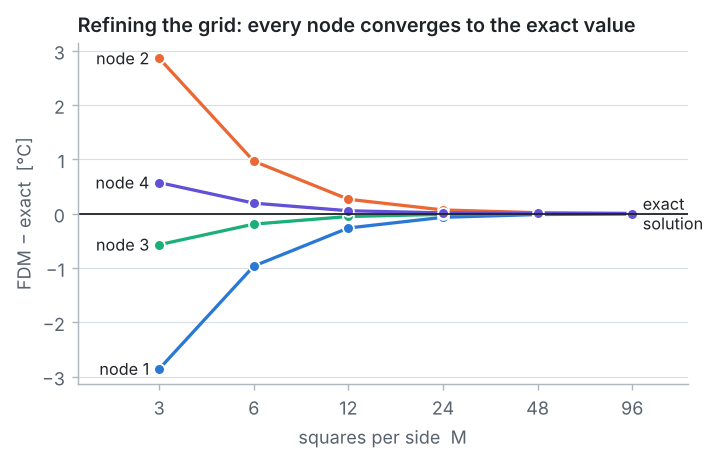

In [18]:
plots.grid_study(Ms, values, exact)

Finally, the whole temperature field on the finest grid. The isotherms bend around the plate, and the four points sit where the coarse grid put them:

In [19]:
T_fine, sweeps = solve_plate(48)
print(f"48 x 48 squares: {47 ** 2} unknowns, converged in {sweeps} SOR sweeps")
print("energy check, sum of q'/k over the four edges:", f"{sum(edge_heat_flows(T_fine, 48).values()):+.4f} K")

48 x 48 squares: 2209 unknowns, converged in 186 SOR sweeps
energy check, sum of q'/k over the four edges: +0.0000 K


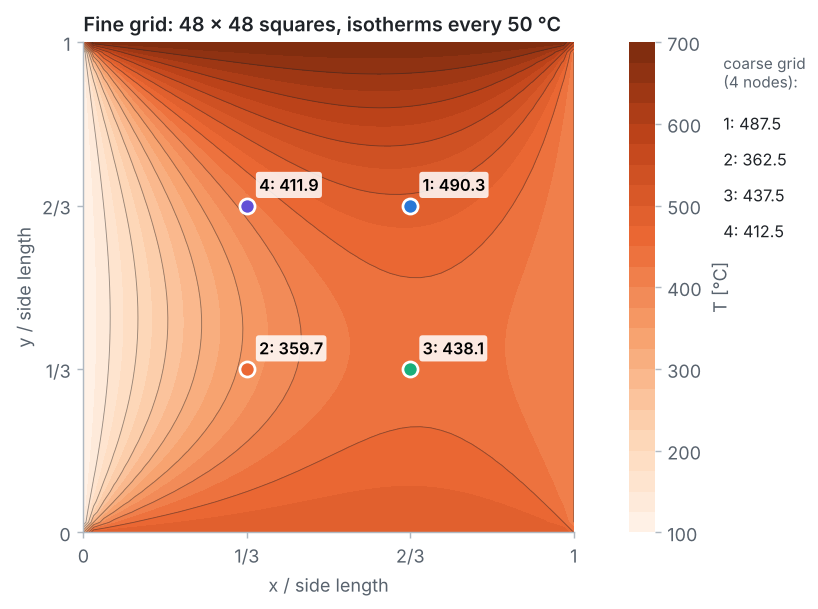

In [20]:
locations = {n: (i / M, j / M) for n, (i, j) in nodes.items()}
plots.field(T_fine, 48, T_solution, locations)

---
## Summary

* Steady 2D conduction obeys the **Laplace equation**; with $\Delta x = \Delta y$ the five-point formula says **each node is the average of its four neighbours**.
* The plate size, the grid spacing and the conductivity all cancel; the corner temperatures are never used.
* The four node equations were solved by **Gaussian elimination** and by **Gauss–Seidel**: $T_1 = 487.5$, $T_2 = 362.5$, $T_3 = 437.5$, $T_4 = 412.5$ °C.
* The discrete solution **conserves energy exactly**: heat in = heat out.
* Refining the grid (with SOR) converges to the exact series solution at second order; the 4-node answer is within 3 °C.

## Try it yourself

1. Start Gauss–Seidel from 0 °C instead of 400 °C. How many more iterations does it need?
2. Change the update in `gauss_seidel` into a **Jacobi** update (only values from the previous iteration). How does the error reduction per iteration change?
3. In `solve_plate`, set `omega = 1.0` (plain Gauss–Seidel) and solve with $M = 48$. How many sweeps are needed now?
4. Compute $T_1 + T_2$ and $T_3 + T_4$. Both equal 850 °C, on every grid! Can you explain why? (*Hint:* rotate the plate by 180°.)
5. Start Gauss–Seidel from 425 °C, the average of the four edge temperatures. It converges in a **single** iteration! Use question 4 to explain why.
6. *Challenge:* make the bottom edge **insulated** instead of 500 °C. How must the equations of nodes 2 and 3 change? (*Hint:* use a ghost node, as in Problem 1.)